# Watts Threshold Model

In [5]:
import networkx as nx
import EoN
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
from scipy import integrate
import math


from matplotlib import rc
#commands to make legend be in LaTeX font
rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
rc('text', usetex=True)



def transition_rate(G, node, status, parameters):
    '''This function needs to return the rate at which \texttt{node} changes status.
    For the model we are assuming, it should return 1 if \texttt{node} has at least
    2 infected partners and 0 otherwise. The information about the threshold
    is provided in the tuple \texttt{parameters}.
    '''
#    r = parameters[0] #the threshold
    #if susceptible and at least \texttt{r} infected partners, then rate is 1
    threshold = parameters[0]
    if status[node] == 'S' and len([nbr for nbr in G.neighbors(node) if
                                    status[nbr] == 'I'])>=threshold[node]:
        return 1
    else:
        return 0

def transition_choice(G, node, status, parameters):
    '''this function needs to return the new status of node. We assume going
    in that we have already calculated it is changing status.
    this function could be more elaborate if there were different
    possible transitions that could happen. However, for this model,
    the 'I' nodes aren't changing status, and the 'S' ones are changing to
    'I'. So if we're in this function, the node must be 'S' and becoming 'I'
    '''
    return 'I'

def get_influence_set(G, node, status, parameters):

    '''this function needs to return a set containing all nodes whose rates
    might change because \texttt{node} has just changed status. That is, which
    nodes might \texttt{node} influence?
    For our models the only nodes a node might affect are the susceptible
    neighbors.
    '''
    return {nbr for nbr in G.neighbors(node) if status[nbr] == 'S'}


In [6]:
def dWTMdt(X, t, N, lamb, psis, w):
    '''
    lamb: the transition rate once the threshold is met (lambda is reserved word)
    psis: a list of functions [psi, psi', psi'', ...]
            #psi(x) = sum_k p_k x^k, where p_k is the degree distribution
            #should be at least one longer than w
    w: a list where w[r] is the fraction of nodes with threshold >r;
        # w[0] = rho_Q
    '''
    assert(len(psis) > len(w))

    psiPrime = psis[1]
    
    theta = X[0] #the probability a random partner of a random node is inactive
    A = X[1] #the fraction of active nodes
    
    S_sum = 0
    phi_sum = 0
    for nA in range(len(w)):
        S_sum += w[nA] * (1-theta)**nA * psis[nA](theta)/math.factorial(nA)
        phi_sum += w[nA] * (1 - theta)**nA * psis[nA+1](theta)/math.factorial(nA) 
        
    S = N * S_sum
    E = N - S - A
    assert E>=-1, "\nA, S, E = {}, {}, {};\n theta, w[1]= {}, {}".format(A, S, E, theta, w[1])

    dAdt = lamb*E
    dthetadt = - lamb * (theta - phi_sum/psiPrime(1))
 #   dthetadt = - lamb * theta * (1 - (1/(w[0]*psiPrime(1))) * phi_sum)
    return np.array([dthetadt, dAdt])

generating graph G with 30000 nodes
[0.9625 0.9625 0.    ]
[0.95535714 0.95535714 0.        ]
[0.94821429 0.94821429 0.        ]
[0.94107143 0.94107143 0.        ]
[0.93392857 0.93392857 0.        ]
[0.92678571 0.92678571 0.        ]
[0.91964286 0.91964286 0.        ]
[0.9125 0.9125 0.    ]


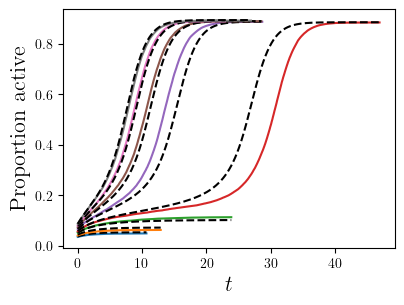

In [ ]:

N = 30000
deg_dist = [2, 4, 6]*int(N/3)
print('generating graph G with {} nodes'.format(N))
G = nx.configuration_model(deg_dist)

P = {2: 1/3, 4: 1/3, 6: 1/3}
psis = [lambda x : sum([p*x**k for k, p in P.items()]), 
        lambda x : sum([k*p*x**(k-1) for k, p in P.items()]),
        lambda x : sum([k*(k-1)*p*x**(k-2) for k, p in P.items()]),
        lambda x : sum([k*(k-1)*(k-2)*p*x**(k-3) for k, p in P.items()]),
        lambda x : sum([k*(k-1)*(k-2)*(k-3)*p*x**(k-4) for k, p in P.items()])
]


thresholds = {node: 2 for node in G.nodes()}
parameters = (thresholds,)  #this is the threshold. Note the comma. It is needed    
                    #for python to realize this is a 1-tuple. \texttt{parameters} is sent as a tuple so we need
                    #the comma.


plt.figure(figsize= (4,3))
for rhoA in np.linspace(3./80, 7./80, 8): #8 values from 3/80 to 7/80.
    #print(rhoA)
    IC = defaultdict(lambda: 'S')
    for node in G.nodes():
        if np.random.random()<rhoA: #there are faster ways to do this random
                                    #selection
            IC[node] = 'I'
    #print('doing Gillespie simulation')
    t, S, I = EoN.Gillespie_complex_contagion(G, transition_rate,
                                    transition_choice, get_influence_set, IC,
                                    return_statuses = ('S', 'I'),
                                    parameters = parameters)
    #print('done with simulation, now plotting')
    plt.plot(t, I/N, label = '$\\rho_A = {:.3f}$'.format(rhoA))

    

    #now do analytic
    rhos = np.array([rhoA, 0, 1-rhoA])


    cum_rhos = np.cumsum(rhos)

    w = 1-cum_rhos 
    #print(w)
    theta0 = 1-rhoA

    assert (theta0 == w[0])

    A0 = N*(rhoA)

    X0 = np.array([theta0, A0])

    t = np.linspace(0, t[-1], 300)

    #print('here', dWTMdt(X0, 0, N, 1, psis, w))
    #break

    X = integrate.odeint(dWTMdt, X0, t, args=(N, 1, psis, w))
    theta = X[:,0]
    A = X[:,1]
    S_sum = 0
    for nA in range(len(w)):
        S_sum += w[nA] * (1-theta)**nA * psis[nA](theta)/math.factorial(nA)
    S = N*S_sum
    E = N - S - A

    plt.plot(t, A/N, '--k')

plt.xlabel('$t$', fontsize=16)
#plt.legend(fontsize=12)
plt.ylabel('Proportion active', fontsize=16)

plt.subplots_adjust(left=0.15, right=0.98, top=0.95, bottom=0.155)
#plt.savefig('WTM.png', dpi=900)
plt.show()

generating graph G with 90000 nodes
0.1
doing Gillespie simulation
done with simulation, now plotting
[0.9  0.9  0.45 0.  ]
0.11666666666666667
doing Gillespie simulation
done with simulation, now plotting
[0.88333333 0.88333333 0.44166667 0.        ]
0.13333333333333333
doing Gillespie simulation
done with simulation, now plotting
[0.86666667 0.86666667 0.43333333 0.        ]
0.15000000000000002
doing Gillespie simulation
done with simulation, now plotting
[0.85  0.85  0.425 0.   ]
0.16666666666666669
doing Gillespie simulation
done with simulation, now plotting
[8.33333333e-01 8.33333333e-01 4.16666667e-01 1.11022302e-16]
0.18333333333333335
doing Gillespie simulation
done with simulation, now plotting
[0.81666667 0.81666667 0.40833333 0.        ]
0.2
doing Gillespie simulation
done with simulation, now plotting
[0.8 0.8 0.4 0. ]


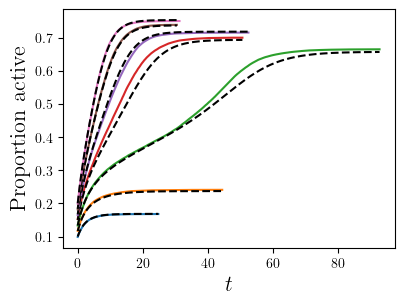

In [ ]:

N = 90000

maxr = 3
P = {2: 1/3, 4: 1/3, 6: 1/3}
psis = [lambda x : sum([p*x**k for k, p in P.items()]), 
        lambda x : sum([k*p*x**(k-1) for k, p in P.items()]),
        lambda x : sum([k*(k-1)*p*x**(k-2) for k, p in P.items()]),
        lambda x : sum([k*(k-1)*(k-2)*p*x**(k-3) for k, p in P.items()]),
        lambda x : sum([k*(k-1)*(k-2)*(k-3)*p*x**(k-4) for k, p in P.items()])
]
assert(len(psis) == maxr + 2)


deg_dist = [2, 4, 6]*int(N/3)
print('generating graph G with {} nodes'.format(N))
G = nx.configuration_model(deg_dist)


thresholds = {node: np.random.choice([2,3], p=[0.5, 0.5]) for node in G.nodes()}
parameters = (thresholds,)  #this is the threshold. Note the comma. It is needed    
                    #for python to realize this is a 1-tuple. \texttt{parameters} is sent as a tuple so we need
                    #the comma.


plt.figure(figsize= (4,3))
for rhoA in np.linspace(0.1, 0.2, 7):
    print(rhoA)
    IC = defaultdict(lambda: 'S')
    for node in G.nodes():
        if np.random.random()<rhoA: #there are faster ways to do this random
                                    #selection
            IC[node] = 'I'
    #print('doing Gillespie simulation')
    t, S, I = EoN.Gillespie_complex_contagion(G, transition_rate,
                                    transition_choice, get_influence_set, IC,
                                    return_statuses = ('S', 'I'),
                                    parameters = parameters)
    #print('done with simulation, now plotting')
    plt.plot(t, I/N, label = '$\\rho_A = {:.3f}$'.format(rhoA))

    

    #now do analytic
    


    rhos = np.array([rhoA, 0, (1-rhoA)*.5, (1-rhoA)*.5])
    cum_rhos = np.cumsum(rhos)

#    w = [ 1 - sum(rho for rho ]
    w = 1-cum_rhos 
    #print(w)
    theta0 = 1-rhoA

    assert (theta0 == w[0])

    A0 = N*(rhoA)

    X0 = np.array([theta0, A0])

    t = np.linspace(0, t[-1], 300)

    #print('here', dWTMdt(X0, 0, N, 1, psis, w))
    #break
    X = integrate.odeint(dWTMdt, X0, t, args=(N, 1, psis, w))
    theta = X[:,0]
    A = X[:,1]
    S_sum = 0
    for nA in range(len(w)):
        S_sum += w[nA] * (1-theta)**nA * psis[nA](theta)/math.factorial(nA)
    S = N*S_sum
    E = N - S - A
    plt.plot(t, A/N, '--k')

plt.xlabel('$t$', fontsize=16)
#plt.legend(fontsize=12)
plt.ylabel('Proportion active', fontsize=16)

plt.subplots_adjust(left=0.15, right=0.98, top=0.95, bottom=0.155)
#plt.savefig('WTMb.png', dpi=900)
plt.show()


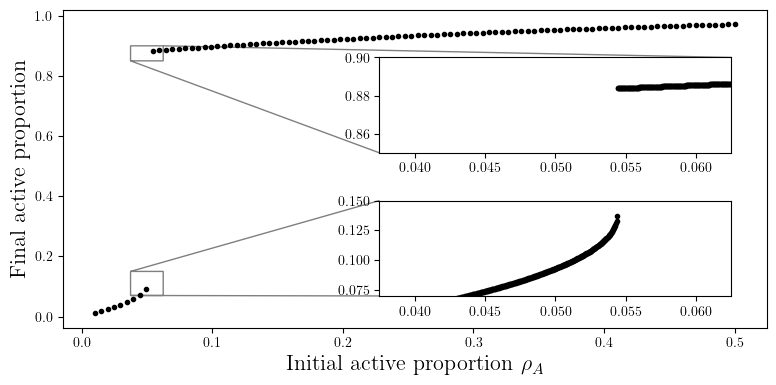

In [9]:


fig, ax = plt.subplots(figsize=(8,4))


rhoA_values = np.linspace(0.01, 0.5, 100)

results = []
for rhoA in rhoA_values:
    rhos = np.array([rhoA, 0, 1-rhoA])
    cum_rhos = np.cumsum(rhos)

#    w = [ 1 - sum(rho for rho ]
    w = 1-cum_rhos 
    #print(w)
    theta0 = 1-rhoA

    assert (theta0 == w[0])

    A0 = N*(rhoA)

    X0 = np.array([theta0, A0])

    t = np.linspace(0, 1000, 300)

    #print('here', dWTMdt(X0, 0, N, 1, psis, w))
    #break
    X = integrate.odeint(dWTMdt, X0, t, args=(N, 1, psis, w))
    theta = X[:,0]
    A = X[:,1]
    results.append(A[-1]/N)
ax.plot(rhoA_values, results, '.k')






rhoA_values = np.linspace(3/80, 6/80, 1001)

results = []
for rhoA in rhoA_values:
    rhos = np.array([rhoA, 0, 1-rhoA])
    cum_rhos = np.cumsum(rhos)

#    w = [ 1 - sum(rho for rho ]
    w = 1-cum_rhos 
    #print(w)
    theta0 = 1-rhoA

    assert (theta0 == w[0])

    A0 = N*(rhoA)

    X0 = np.array([theta0, A0])

    t = np.linspace(0, 1000, 300)

    #print('here', dWTMdt(X0, 0, N, 1, psis, w))
    #break
    X = integrate.odeint(dWTMdt, X0, t, args=(N, 1, psis, w))
    theta = X[:,0]
    A = X[:,1]
    results.append(A[-1]/N)


inset1 = ax.inset_axes([0.45,0.1,0.5,0.3],
                 xlim=(3/80,5/80), ylim=(0.07, 0.15))
inset1.plot(rhoA_values, results, '.k')

inset2 = ax.inset_axes([0.45,0.55,0.5,0.3],
                 xlim=(3/80,5/80), ylim=(0.85, 0.9))
inset2.plot(rhoA_values, results, '.k')

ax.indicate_inset_zoom(inset1, edgecolor="black")
ax.indicate_inset_zoom(inset2, edgecolor="black")

plt.xlabel('Initial active proportion $\\rho_A$', fontsize=16)
plt.ylabel('Final active proportion', fontsize=16)
plt.subplots_adjust(left=0.1, right=0.98, top=0.95, bottom=0.155)
#plt.savefig('WTM_final_size.png', dpi=900)
plt.show()